# Neural Networks and Deep Learning — Lecture 11: Explainable AI: SHAP, LIME, gradient methods and the stability of explanations
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies (ASE); Romanian Academy, Institute for Economic Forecasting (IPE)

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L11_notebook.ipynb)

This notebook reproduces the numbers and charts of the lecture from the real data in `../data/clean` (see `../data/SOURCES.md`). Section numbers (§) match the *Experiment yourself* pointers on the slides.

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


## §1 Credit data (HMEQ) and the models to explain

In [3]:
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
import shap
from lime.lime_tabular import LimeTabularExplainer
torch.set_num_threads(4)
class MLP(nn.Module):
    def __init__(self, d, h1=64, h2=32, p=0.1):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(d, h1), nn.ReLU(), nn.Dropout(p), nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(p), nn.Linear(h2, 1))
    def forward(self, x): return self.f(x).squeeze(-1)
def train_mlp(seed, Xa, ya, Xv, yv, w_pos=1.0, epochs=300, patience=25, task='clf', lr=1e-3):
    torch.manual_seed(seed); rng = np.random.default_rng(seed); net = MLP(Xa.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    Xt, yt = torch.from_numpy(Xa), torch.from_numpy(ya.astype(np.float32)); best, state, bad = -np.inf, None, 0
    for ep in range(epochs):
        net.train(); perm = rng.permutation(len(Xa))
        for j in range(0, len(Xa), 256):
            b = torch.from_numpy(perm[j:j + 256]); out = net(Xt[b])
            if task == 'clf':
                w = torch.where(yt[b] > 0, torch.tensor(w_pos), torch.tensor(1.0))
                loss = nn.functional.binary_cross_entropy_with_logits(out, yt[b], weight=w)
            else:
                loss = ((out - yt[b]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): pv = net(torch.from_numpy(Xv)).numpy()
        sc = (roc_auc_score(yv, pv) if w_pos == 1.0 else average_precision_score(yv, pv)) if task == 'clf' else -np.mean((pv - yv) ** 2)
        if sc > best: best, state, bad = sc, {k: v.clone() for k, v in net.state_dict().items()}, 0
        else:
            bad += 1
            if bad > patience: break
    net.load_state_dict(state); net.eval(); return net
def logit_fn(net):
    def f(X):
        with torch.no_grad(): return net(torch.from_numpy(np.asarray(X, dtype=np.float32))).numpy().astype(np.float64)
    return f
sig = lambda z: 1 / (1 + np.exp(-z))

In [4]:
h = pd.read_csv(DATA + 'hmeq.csv')
NUM = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
JOBS = ['Mgr', 'Office', 'Other', 'ProfExe', 'Sales', 'Self']
y_all = h['BAD'].values; idx = np.arange(len(h))
i_tr, i_te = train_test_split(idx, test_size=0.2, stratify=y_all, random_state=SEED)
i_tr, i_va = train_test_split(i_tr, test_size=0.25, stratify=y_all[i_tr], random_state=SEED)
med = h.iloc[i_tr][NUM].median()
XR = pd.DataFrame({c: h[c].fillna(med[c]) for c in NUM})
XR['DEBTINC_missing'] = h['DEBTINC'].isna().astype(float); XR['REASON_HomeImp'] = (h['REASON'] == 'HomeImp').astype(float)
for j in JOBS: XR['JOB_' + j] = (h['JOB'] == j).astype(float)
FEATS = list(XR.columns); mu, sd = XR.iloc[i_tr].mean(), XR.iloc[i_tr].std()
XS = ((XR - mu) / sd).values.astype(np.float32)
Xtr, Xva, Xte = XS[i_tr], XS[i_va], XS[i_te]; ytr, yva, yte = y_all[i_tr], y_all[i_va], y_all[i_te]
print(len(h), 'loans;', round(100 * y_all.mean(), 1), '% defaults;', len(FEATS), 'features')

5960 loans; 19.9 % defaults; 18 features


In [5]:
net = train_mlp(SEED, Xtr, ytr, Xva, yva); f0 = logit_fn(net)
lr = LogisticRegression(C=1.0, max_iter=2000).fit(Xtr, ytr)
for name, p in (('MLP', sig(f0(Xte))), ('logistic', lr.predict_proba(Xte)[:, 1])):
    print(f'{name:9s} AUC {roc_auc_score(yte, p):.3f}  PR-AUC {average_precision_score(yte, p):.3f}')

MLP       AUC 0.937  PR-AUC 0.840
logistic  AUC 0.909  PR-AUC 0.785


## §2 Kernel SHAP: global importance, beeswarm, one applicant

In [6]:
rng = np.random.default_rng(SEED)
BG = Xtr[rng.choice(len(Xtr), 100, replace=False)]
i_sub = rng.choice(len(Xte), 400, replace=False); Xsub = Xte[i_sub]
np.random.seed(SEED); ex = shap.KernelExplainer(f0, BG)
sv = np.array(ex.shap_values(Xsub[:150], nsamples=400, silent=True)); base = f0(BG).mean()
print('additivity error:', np.abs(sv.sum(1) + base - f0(Xsub[:150])).max())
imp = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(ascending=False); print(imp.head(8).round(3))
sv_lr = (Xsub[:150] - BG.mean(0)) * lr.coef_[0]   # linear SHAP of the logistic regression
print('linear SHAP top features:', list(pd.Series(np.abs(sv_lr).mean(0), index=FEATS).sort_values(ascending=False).index[:5]))

additivity error: 1.9073486328125e-06
DEBTINC_missing    1.350
DELINQ             1.220
JOB_Other          1.147
JOB_ProfExe        0.961
DEBTINC            0.560
CLAGE              0.537
CLNO               0.506
DEROG              0.354
dtype: float64
linear SHAP top features: ['DEBTINC_missing', 'DELINQ', 'JOB_Other', 'DEBTINC', 'CLAGE']


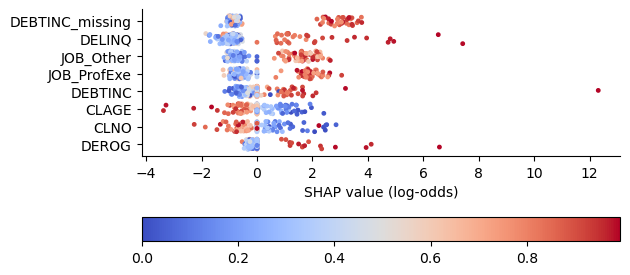

In [7]:
top = imp.index[:8][::-1]
fig, ax = plt.subplots(figsize=(6.4, 2.9))
for row, f in enumerate(top):
    j = FEATS.index(f); q = Xsub[:150, j].argsort().argsort() / 150
    sc = ax.scatter(sv[:, j], row + (np.random.default_rng(j).random(150) - 0.5) * 0.6, c=q, cmap='coolwarm', s=6)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top); ax.set_xlabel('SHAP value (log-odds)'); plt.colorbar(sc, orientation='horizontal', pad=0.25)
fig.tight_layout(); plt.show()

In [8]:
p_sub = sig(f0(Xsub[:150]))
cand = np.where((p_sub > 0.5) & (p_sub < 0.8) & (yte[i_sub[:150]] == 1))[0]
k = int(cand[np.argmin(np.abs(p_sub[cand] - 0.65))]) if len(cand) else int(np.argmax(p_sub)); x_app = Xsub[k]
phi = pd.Series(sv[k], index=FEATS); print('PD', round(100 * p_sub[k], 1), '%; base log-odds', round(base, 3))
print(phi.reindex(phi.abs().sort_values(ascending=False).index).head(6).round(3))

PD 63.1 %; base log-odds -3.613
DEBTINC_missing    3.318
JOB_Other          1.348
DELINQ            -0.804
YOJ                0.393
CLNO               0.390
JOB_ProfExe       -0.314
dtype: float64


## §3 LIME and its sensitivity to its own settings

In [9]:
def lime_w(x, n=5000, kw=None, seed=0):
    e = LimeTabularExplainer(Xtr, mode='regression', feature_names=FEATS, discretize_continuous=False, sample_around_instance=True,
                             random_state=seed, kernel_width=kw).explain_instance(x, f0, num_features=len(FEATS), num_samples=n)
    w = np.zeros(len(FEATS))
    for j, v in e.local_exp[0]: w[j] = v
    return w
W500 = np.array([lime_w(x_app, 500, seed=s) for s in range(15)]); W5k = np.array([lime_w(x_app, 5000, seed=s) for s in range(15)])
top1 = lambda W: np.mean([np.argmax(np.abs(w)) == np.argmax(np.abs(W5k[0])) for w in W])
print('same top feature, 500 samples:', top1(W500), '| 5,000 samples:', top1(W5k))
for kw in (0.5, 1, 2, 4.12, 10):
    w = lime_w(x_app, kw=kw); print('kernel width', kw, '-> top feature', FEATS[int(np.argmax(np.abs(w)))], round(w.max(), 3))

same top feature, 500 samples: 0.9333333333333333 | 5,000 samples: 1.0
kernel width 0.5 -> top feature JOB_Sales 0.001
kernel width 1 -> top feature DELINQ 0.981
kernel width 2 -> top feature DELINQ 1.039
kernel width 4.12 -> top feature DELINQ 1.032
kernel width 10 -> top feature DELINQ 1.031


## §4 A counterfactual explanation

In [10]:
ACTION = ['LOAN', 'DEBTINC', 'NINQ', 'DELINQ', 'DEROG', 'CLNO', 'MORTDUE']
mad = (XR.iloc[i_tr][NUM] - XR.iloc[i_tr][NUM].median()).abs().median().replace(0, np.nan).fillna(XR.iloc[i_tr][NUM].std())
m = torch.tensor([1.0 if f in ACTION else 0.0 for f in FEATS]); scale = torch.tensor([sd[f] / mad[f] if f in ACTION else 0.0 for f in FEATS], dtype=torch.float32)
x0 = torch.tensor(x_app); x = x0.clone().requires_grad_(True); opt = torch.optim.Adam([x], lr=0.01)
for _ in range(3000):
    xx = x0 + m * (x - x0); loss = 10 * net(xx[None])[0] ** 2 + (scale * (xx - x0).abs()).sum()
    opt.zero_grad(); loss.backward(); opt.step()
xc = (x0 + m * (x - x0)).detach().numpy(); raw0, raw1 = x_app * sd.values + mu.values, xc * sd.values + mu.values
print('PD before', round(100 * sig(f0(x_app[None])[0]), 1), '% -> after', round(100 * sig(f0(xc[None])[0]), 1), '%')
print(pd.DataFrame({'before': raw0, 'after': raw1}, index=FEATS).loc[ACTION].round(1))

PD before 63.1 % -> after 50.3 %
          before    after
LOAN     18000.0  18006.2
DEBTINC     34.7     34.7
NINQ         2.0      2.0
DELINQ      -0.0     -0.1
DEROG       -0.0     -0.0
CLNO        14.0     14.0
MORTDUE  57988.0  57955.8


## §5 Fraud: saliency, gradient x input, SmoothGrad, integrated gradients

In [11]:
fr = pd.read_csv(DATA + 'creditcard_fraud_sample.csv'); fr['logAmount'] = np.log1p(fr['Amount'])
FF = [f'V{i}' for i in range(1, 29)] + ['logAmount']; d1, d2 = fr[fr.Time < 86400], fr[fr.Time >= 86400]
j_tr, j_va = train_test_split(np.arange(len(d1)), test_size=0.25, stratify=d1['Class'], random_state=SEED)
fmu, fsd = d1.iloc[j_tr][FF].mean(), d1.iloc[j_tr][FF].std()
Z1 = ((d1[FF] - fmu) / fsd).values.astype(np.float32); Z2 = ((d2[FF] - fmu) / fsd).values.astype(np.float32)
y1, y2, w1, w2 = d1['Class'].values, d2['Class'].values, d1['weight'].values, d2['weight'].values
pw = float((w1[j_tr] * (1 - y1[j_tr])).sum() / (w1[j_tr] * y1[j_tr]).sum()) ** 0.5
fnet = train_mlp(SEED, Z1[j_tr], y1[j_tr], Z1[j_va], y1[j_va], w_pos=pw, epochs=200, patience=20); ff = logit_fn(fnet)
print('day 2 weighted PR-AUC:', round(average_precision_score(y2, ff(Z2), sample_weight=w2), 3))
base_f = Z1[j_tr][y1[j_tr] == 0].mean(0); F2 = Z2[y2 == 1]
def grad_of(X):
    x = torch.tensor(np.asarray(X, dtype=np.float32), requires_grad=True); g, = torch.autograd.grad(fnet(x).sum(), x); return g.numpy()
def ig(X, m=64):
    tot = np.zeros_like(X)
    for a in (np.arange(m) + 0.5) / m: tot += grad_of(base_f + a * (X - base_f))
    return (X - base_f) * tot / m
gap = ff(F2) - ff(base_f[None])[0]
for m_ in (4, 16, 64, 256):
    print('IG steps', m_, 'median completeness error %:', round(100 * np.median(np.abs(ig(F2, m_).sum(1) - gap) / np.abs(gap)), 3))

day 2 weighted PR-AUC: 0.816
IG steps 4 median completeness error %: 5.414
IG steps 16 median completeness error %: 1.56
IG steps 64 median completeness error %: 0.225
IG steps 256 median completeness error %: 0.067


## §6 Do the methods agree? Faithfulness (deletion) and local robustness

In [12]:
from scipy import stats
A = {'saliency': np.abs(grad_of(F2)), 'gradxinput': grad_of(F2) * (F2 - base_f), 'ig': ig(F2)}
G = pd.DataFrame({k: np.abs(v).mean(0) for k, v in A.items()}, index=FF)
print(G.corr(method='spearman').round(2))
def deletion(Am, K=12):
    out = np.zeros(K + 1)
    for i, x in enumerate(F2):
        o = np.argsort(-np.abs(Am[i])); xs = np.repeat(x[None], K + 1, 0)
        for k in range(1, K + 1): xs[k:, o[k - 1]] = base_f[o[k - 1]]
        out += sig(ff(xs))
    return out / len(F2)
for k_, v in A.items(): print(k_, 'score after resetting 3 features:', round(100 * deletion(v)[3], 1), '%')

            saliency  gradxinput    ig
saliency        1.00        0.89  0.87
gradxinput      0.89        1.00  0.97
ig              0.87        0.97  1.00


saliency score after resetting 3 features: 55.6 %
gradxinput score after resetting 3 features: 49.3 %
ig score after resetting 3 features: 48.7 %


## §7 Stability: three training seeds and the shift from day 1 to day 2

In [13]:
ranks = []
for s in range(3):
    n_ = train_mlp(SEED + s, Xtr, ytr, Xva, yva); e_ = shap.KernelExplainer(logit_fn(n_), BG)
    v = np.array(e_.shap_values(Xsub[:80], nsamples=300, silent=True)); ranks.append(stats.rankdata(-np.abs(v).mean(0)))
    print('seed', SEED + s, 'AUC', round(roc_auc_score(yte, logit_fn(n_)(Xte)), 3), 'top-3', [FEATS[j] for j in np.argsort(ranks[-1])[:3]])
print('Kendall tau seed 1 vs 2:', round(stats.kendalltau(ranks[0], ranks[1])[0], 2))
F1v = Z1[j_va][y1[j_va] == 1]; g1, g2 = np.abs(ig(F1v)).mean(0), np.abs(A['ig']).mean(0)
print('Spearman day 1 vs day 2 (IG importances):', round(stats.spearmanr(g1, g2)[0], 2))

seed 20261108 AUC 0.937 top-3 ['DEBTINC_missing', 'JOB_Other', 'DELINQ']


seed 20261109 AUC 0.933 top-3 ['DEBTINC_missing', 'JOB_ProfExe', 'DELINQ']


seed 20261110 AUC 0.935 top-3 ['DEBTINC_missing', 'JOB_Other', 'DELINQ']
Kendall tau seed 1 vs 2: 0.8
Spearman day 1 vs day 2 (IG importances): 0.98


## §8 Partial dependence and ICE on California housing

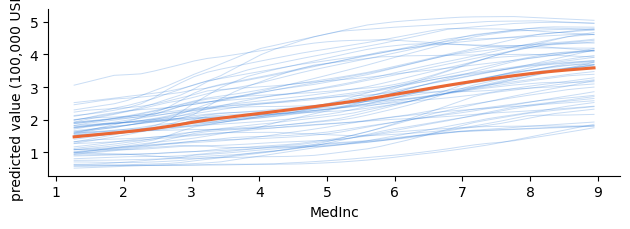

In [14]:
ca = pd.read_csv(DATA + 'california_housing.csv'); CF = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
k_tr, k_te = train_test_split(np.arange(len(ca)), test_size=0.2, random_state=SEED); k_tr, k_va = train_test_split(k_tr, test_size=0.2, random_state=SEED)
cmu, csd = ca.iloc[k_tr][CF].mean(), ca.iloc[k_tr][CF].std(); CZ = ((ca[CF] - cmu) / csd).values.astype(np.float32)
cy = ca['MedHouseVal_100k_usd'].values.astype(np.float32)
cnet = train_mlp(SEED, CZ[k_tr], cy[k_tr], CZ[k_va], cy[k_va], task='reg', epochs=200, patience=20, lr=2e-3); cf = logit_fn(cnet)
grid = np.linspace(np.percentile(ca.MedInc, 2), np.percentile(ca.MedInc, 98), 40); gz = (grid - cmu['MedInc']) / csd['MedInc']
rows = CZ[k_te][np.random.default_rng(SEED).choice(len(k_te), 60, replace=False)]
ice = np.array([[cf(np.c_[np.full(1, z), r[None, 1:]])[0] for z in gz] for r in rows])
fig, ax = plt.subplots(figsize=(6.4, 2.4)); ax.plot(grid, ice.T, color='#2a78d6', alpha=0.25, lw=0.7); ax.plot(grid, ice.mean(0), color='#eb6834', lw=2.2)
ax.set_xlabel('MedInc'); ax.set_ylabel('predicted value (100,000 USD)'); fig.tight_layout(); plt.show()